<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    import libraries & Load the data
</h6>

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data").exists():
    ROOT_DIR = ROOT_DIR.parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.data.load_data import load_all_tables
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

tables = load_all_tables()
orders = tables["orders"].copy()
items = tables["order_items"].copy()
payments = tables["payments"].copy()
products = tables["products"].copy()
customers = tables["customers"].copy()
sellers = tables["sellers"].copy()
categories = tables["category_translation"].copy()

print("Orders:", orders.shape)
print("Items:", items.shape)
print("Payments:", payments.shape)

Orders: (99441, 8)
Items: (112650, 7)
Payments: (103886, 5)


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Target Construction
</h6>

In [2]:
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

eda_orders = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

eda_orders["is_late"] = (
    eda_orders["order_delivered_customer_date"]
    > eda_orders["order_estimated_delivery_date"]
).astype(int)

eda_orders["delivery_delay_days"] = (
    eda_orders["order_delivered_customer_date"]
    - eda_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

eda_orders["late_days"] = eda_orders["delivery_delay_days"].clip(lower=0)

eda_orders["estimated_lead_days"] = (
    eda_orders["order_estimated_delivery_date"]
    - eda_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("EDA dataset shape:", eda_orders.shape)
print("\nTarget distribution:")
print(eda_orders["is_late"].value_counts())

print("\nTarget percentages:")
print(eda_orders["is_late"].value_counts(normalize=True) * 100)

EDA dataset shape: (96470, 12)

Target distribution:
is_late
0    88644
1     7826
Name: count, dtype: int64

Target percentages:
is_late
0    91.887633
1     8.112367
Name: proportion, dtype: float64


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Target Distribution
</h6>

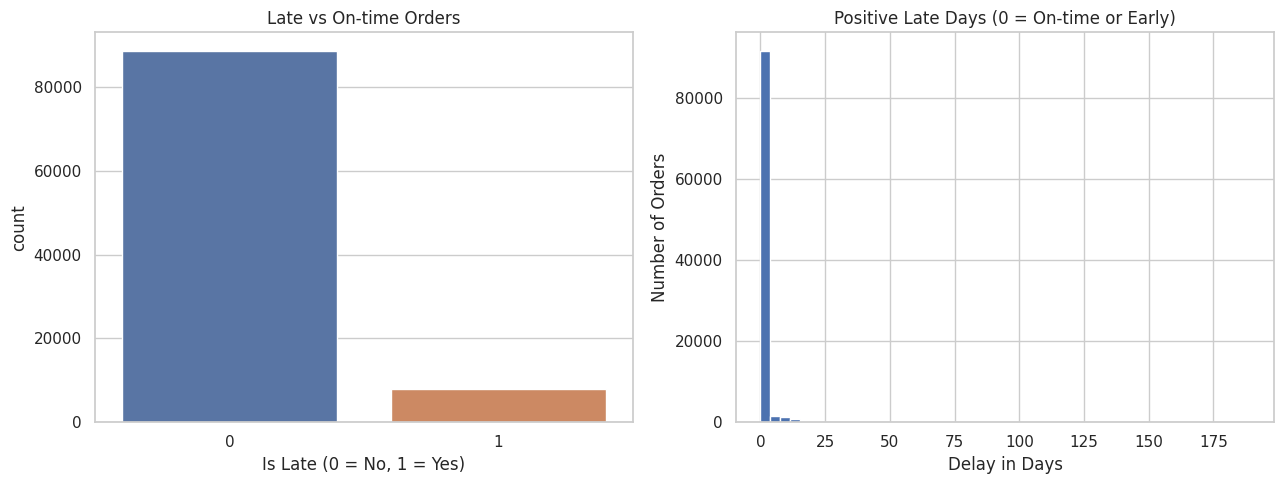

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=eda_orders,
    x="is_late",
    hue="is_late",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Late vs On-time Orders")
axes[0].set_xlabel("Is Late (0 = No, 1 = Yes)")

eda_orders["late_days"].hist(
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Positive Late Days (0 = On-time or Early)")
axes[1].set_xlabel("Delay in Days")
axes[1].set_ylabel("Number of Orders")

plt.tight_layout()
plt.show()

<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Monthly Late Delivery Rate
</h6>

,purchase_month,order_count,late_count,late_rate
0,2016-09,1,1,100.000000
1,2016-10,265,3,1.132075
2,2016-12,1,0,0.000000
3,2017-01,750,23,3.066667
4,2017-02,1653,53,3.206292
5,2017-03,2546,142,5.577376
6,2017-04,2303,181,7.859314
7,2017-05,3545,128,3.610719
8,2017-06,3135,121,3.859649
9,2017-07,3872,133,3.434917


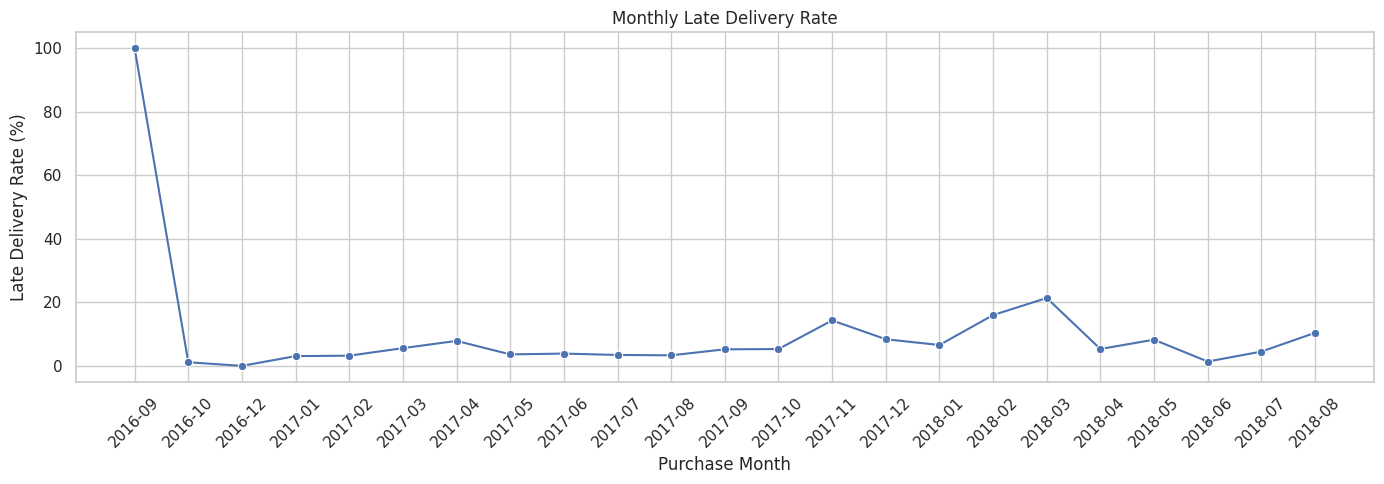

,purchase_month,order_count,late_count,late_rate
0,2016-09,1,1,100.000000
1,2016-10,265,3,1.132075
2,2016-12,1,0,0.000000
3,2017-01,750,23,3.066667
4,2017-02,1653,53,3.206292
5,2017-03,2546,142,5.577376
6,2017-04,2303,181,7.859314
7,2017-05,3545,128,3.610719
8,2017-06,3135,121,3.859649
9,2017-07,3872,133,3.434917


In [4]:
eda_orders["purchase_month"] = eda_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)

eda_orders["delivery_deviation_days"] = (
    eda_orders["order_delivered_customer_date"]
    - eda_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

eda_orders["late_days"] = (
    eda_orders["delivery_deviation_days"].clip(lower=0)
)

monthly_late_rate = (
    eda_orders.groupby("purchase_month")
    .agg(
        order_count=("is_late", "size"),
        late_count=("is_late", "sum"),
        late_rate=("is_late", "mean"),
    )
    .reset_index()
)

monthly_late_rate["late_rate"] *= 100

display(monthly_late_rate)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_late_rate,
    x="purchase_month",
    y="late_rate",
    marker="o"
)

plt.title("Monthly Late Delivery Rate")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly_late_rate

<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Purchase Time Analysis
</h6>

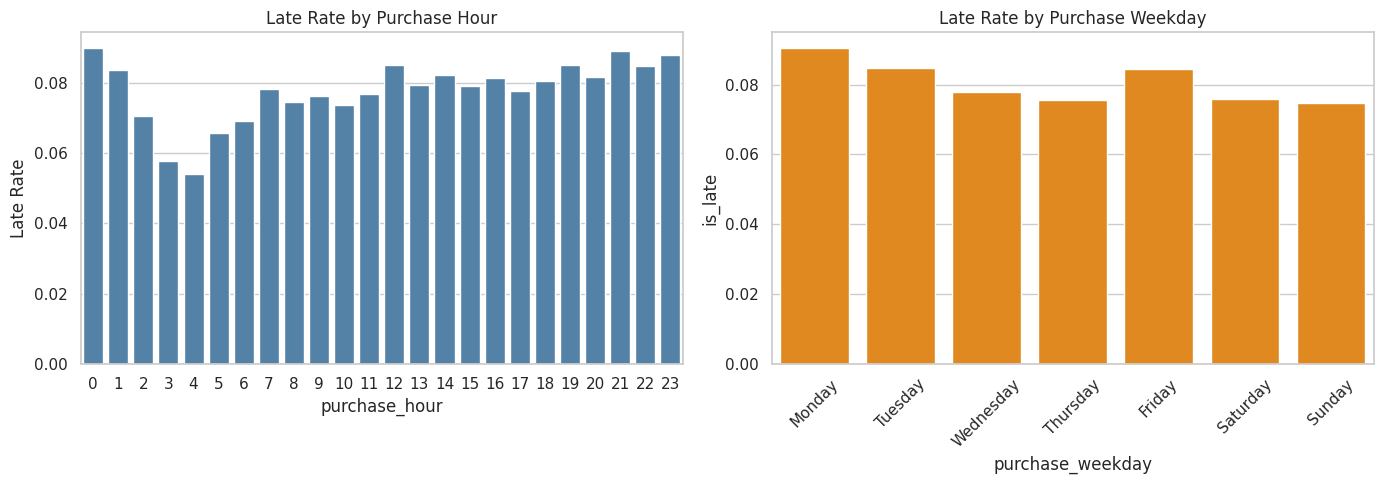

In [5]:
eda_orders["purchase_hour"] = (eda_orders["order_purchase_timestamp"].dt.hour)
eda_orders["purchase_weekday"] = (eda_orders["order_purchase_timestamp"].dt.day_name())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=eda_orders,
    x="purchase_hour",
    y="is_late",
    errorbar=None,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Late Rate by Purchase Hour")
axes[0].set_ylabel("Late Rate")

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

sns.barplot(
    data=eda_orders,
    x="purchase_weekday",
    y="is_late",
    order=weekday_order,
    errorbar=None,
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Late Rate by Purchase Weekday")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Order-Level Aggregations
</h6>

In [6]:
items_agg = (
    items.groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        seller_count=("seller_id", "nunique"),
        product_count=("product_id", "nunique"),
    )
    .reset_index()
)

payments_agg = (
    payments.groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        payment_types=("payment_type", "nunique"),
    )
    .reset_index()
)

eda_orders = (
    eda_orders
    .merge(items_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
)

eda_orders[
    [
        "is_late",
        "item_count",
        "total_price",
        "total_freight",
        "seller_count",
        "payment_value",
        "estimated_lead_days",
    ]
].describe()

,is_late,item_count,total_price,total_freight,seller_count,payment_value,estimated_lead_days
count,96470.000000,96470.000000,96470.000000,96470.000000,96470.000000,96469.000000,96470.000000
mean,0.081124,1.142210,137.040001,22.785798,1.013901,159.855320,23.736343
std,0.273026,0.538824,209.052608,21.559959,0.123542,218.820934,8.761052
min,0.000000,1.000000,0.850000,0.000000,1.000000,9.590000,2.008009
25%,0.000000,1.000000,45.900000,13.850000,1.000000,61.880000,18.329905
50%,0.000000,1.000000,86.500000,17.170000,1.000000,105.280000,23.230880
75%,0.000000,1.000000,149.900000,24.020000,1.000000,176.330000,28.407795
max,1.000000,21.000000,13440.000000,1794.960000,5.000000,13664.080000,155.135463


<h6 style="font-size:50px; font-family:Garamond; font-weight:normal; background-color:#3E8E7E; color:#FFFFFF; text-align:center; border-radius:5px 5px; padding:5px">
    Numerical Features vs Late Delivery
</h6>

,On-time,Late
item_count,1.144748,1.113468
total_price,136.064803,148.085933
total_freight,22.623544,24.623620
seller_count,1.014925,1.002300
payment_value,158.718425,172.734414
estimated_lead_days,23.892540,21.967114


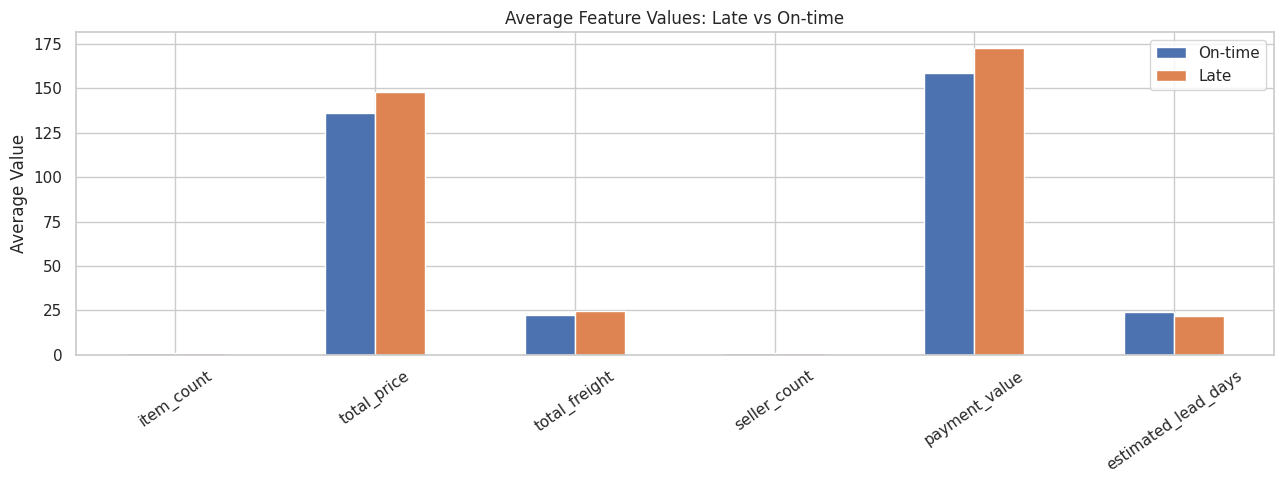

In [7]:
numeric_features = [
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "payment_value",
    "estimated_lead_days",
]

late_analysis = (eda_orders.groupby("is_late")[numeric_features].mean().T)

late_analysis.columns = ["On-time", "Late"]

display(late_analysis)

late_analysis.plot(
    kind="bar",
    figsize=(13, 5)
)

plt.title("Average Feature Values: Late vs On-time")
plt.ylabel("Average Value")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()